In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_PATH = Path("../data/real_estate_data.xlsx")

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (2135, 14)


,property_id,location,area_sqm,bedrooms,bathrooms,property_type,building_age,floor,total_floors,has_parking,has_elevator,distance_to_center_km,renovation_status,price
0,PRP00587,Nasimi,108.7,3,2.0,apartment,4.0,10.0,17,True,True,NaN,renovated,466000
1,PRP00469,Nasimi,118.1,3,2.0,apartment,9.0,13.0,17,False,True,2.68,needs_renovation,244000
2,PRP00645,Baku,80.7,2,1.0,apartment,NaN,22.0,24,False,True,10.32,good,117000
3,PRP02022,Sabail,294.3,8,5.0,house,48.0,3.0,3,True,False,2.67,needs_renovation,506000
4,PRP01131,Binagadi,96.6,3,2.0,apartment,40.0,4.0,16,True,True,3.55,needs_renovation,76000


### Part 1: Data Loading and Inspection

##### Find the number of rows and columns


In [105]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Total cells: {df.size}")

Number of rows: 2135
Number of columns: 14
Total cells: 29890


##### Inspect column names, data types, and non-null values.


In [106]:
df.info()

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

<class 'pandas.DataFrame'>
RangeIndex: 2135 entries, 0 to 2134
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   property_id            2135 non-null   str    
 1   location               2135 non-null   str    
 2   area_sqm               2103 non-null   float64
 3   bedrooms               2135 non-null   int64  
 4   bathrooms              2090 non-null   float64
 5   property_type          2135 non-null   str    
 6   building_age           2082 non-null   float64
 7   floor                  2114 non-null   float64
 8   total_floors           2135 non-null   int64  
 9   has_parking            2135 non-null   bool   
 10  has_elevator           2135 non-null   bool   
 11  distance_to_center_km  2103 non-null   float64
 12  renovation_status      2069 non-null   str    
 13  price                  2135 non-null   int64  
dtypes: bool(2), float64(5), int64(3), str(4)
memory usage: 204.5 KB

Co

,Data Type
property_id,str
location,str
area_sqm,float64
bedrooms,int64
bathrooms,float64
property_type,str
building_age,float64
floor,float64
total_floors,int64
has_parking,bool


##### Calculate descriptive statistics.


In [107]:
display(df.describe().T)

print("\nDescriptive statistics for all columns:")
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
area_sqm,2103.0,151.882073,96.124588,53.9,102.75,124.6,160.750,1320.00
bedrooms,2135.0,3.777518,1.676694,1.0,3.00,3.0,4.000,10.00
bathrooms,2090.0,2.205263,0.999986,1.0,2.00,2.0,3.000,8.00
building_age,2082.0,22.247839,14.949830,1.0,11.00,19.0,30.000,112.00
floor,2114.0,5.654210,4.636030,1.0,2.00,4.0,8.000,24.00
total_floors,2135.0,10.428103,6.320431,1.0,5.00,10.0,15.000,25.00
distance_to_center_km,2103.0,6.240014,4.253138,0.3,3.10,4.9,8.525,25.35
price,2135.0,285081.451991,258097.736591,37500.0,155250.00,222000.0,319000.000,4100000.00



Descriptive statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
property_id,2135,2100,PRP00659,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,2135,7,Binagadi,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_sqm,2103.0,NaN,NaN,NaN,151.882073,96.124588,53.9,102.75,124.6,160.75,1320.0
bedrooms,2135.0,NaN,NaN,NaN,3.777518,1.676694,1.0,3.0,3.0,4.0,10.0
bathrooms,2090.0,NaN,NaN,NaN,2.205263,0.999986,1.0,2.0,2.0,3.0,8.0
property_type,2135,3,apartment,1705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
building_age,2082.0,NaN,NaN,NaN,22.247839,14.94983,1.0,11.0,19.0,30.0,112.0
floor,2114.0,NaN,NaN,NaN,5.65421,4.63603,1.0,2.0,4.0,8.0,24.0
total_floors,2135.0,NaN,NaN,NaN,10.428103,6.320431,1.0,5.0,10.0,15.0,25.0
has_parking,2135,2,False,1125,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Count duplicate records.


In [108]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate records: {duplicate_count}")

display(df.loc[df.duplicated(keep=False)].sort_index())

Number of duplicate records: 35


,property_id,location,area_sqm,bedrooms,bathrooms,property_type,building_age,floor,total_floors,has_parking,has_elevator,distance_to_center_km,renovation_status,price
83,PRP00659,Baku,78.6,2,1.0,apartment,23.0,2.0,11,True,True,9.24,renovated,138000
160,PRP00201,Khatai,444.3,8,NaN,villa,8.0,1.0,1,True,False,7.84,good,954000
195,PRP01680,Narimanov,425.4,8,4.0,villa,37.0,2.0,2,True,False,3.34,needs_renovation,835500
218,PRP01253,Nasimi,98.9,3,2.0,apartment,32.0,3.0,10,False,True,1.10,needs_renovation,221500
249,PRP00141,Narimanov,115.6,2,1.0,apartment,9.0,5.0,10,True,True,3.62,good,263000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2027,PRP00926,Nasimi,114.7,2,1.0,apartment,21.0,4.0,10,True,True,3.62,needs_renovation,262000
2063,PRP01078,Narimanov,90.3,2,1.0,apartment,27.0,2.0,12,False,True,3.05,renovated,189000
2080,PRP01680,Narimanov,425.4,8,4.0,villa,37.0,2.0,2,True,False,3.34,needs_renovation,835500
2090,PRP01307,Baku,134.0,4,2.0,apartment,21.0,3.0,16,False,True,11.67,NaN,183500


##### Calculate missing values and their percentages.


In [109]:
missing_data = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean().mul(100),
    "Non-Missing Count": df.notnull().sum()
})

missing_data = missing_data.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_data)

print("\nColumns containing missing values:")
display(missing_data[missing_data["Missing Count"] > 0])

,Missing Count,Missing Percentage,Non-Missing Count
renovation_status,66,3.091335,2069
building_age,53,2.482436,2082
bathrooms,45,2.107728,2090
distance_to_center_km,32,1.498829,2103
area_sqm,32,1.498829,2103
floor,21,0.983607,2114
property_type,0,0.000000,2135
bedrooms,0,0.000000,2135
property_id,0,0.000000,2135
location,0,0.000000,2135



Columns containing missing values:


,Missing Count,Missing Percentage,Non-Missing Count
renovation_status,66,3.091335,2069
building_age,53,2.482436,2082
bathrooms,45,2.107728,2090
distance_to_center_km,32,1.498829,2103
area_sqm,32,1.498829,2103
floor,21,0.983607,2114


##### Identify numerical and categorical columns.

In [110]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['area_sqm', 'bedrooms', 'bathrooms', 'building_age', 'floor', 'total_floors', 'distance_to_center_km', 'price']

Categorical columns:
['property_id', 'location', 'property_type', 'has_parking', 'has_elevator', 'renovation_status']


##### Count unique values in each column.

In [111]:
unique_counts = pd.DataFrame({
    "Unique Values": df.nunique(dropna=True),
    "Missing Values": df.isnull().sum()
})

display(unique_counts.sort_values(
    by="Unique Values",
    ascending=False
))

,Unique Values,Missing Values
property_id,2100,0
area_sqm,1192,32
distance_to_center_km,1034,32
price,893,0
building_age,75,53
total_floors,25,0
floor,24,21
bedrooms,10,0
bathrooms,8,45
location,7,0


##### Identify the target variable and input features.

In [112]:
target_column = "price"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

X = df.drop(columns=[target_column])
y = df[target_column]

print("Target variable:", target_column)
print("Number of input features:", X.shape[1])
print("Input features:", X.columns.tolist())

Target variable: price
Number of input features: 13
Input features: ['property_id', 'location', 'area_sqm', 'bedrooms', 'bathrooms', 'property_type', 'building_age', 'floor', 'total_floors', 'has_parking', 'has_elevator', 'distance_to_center_km', 'renovation_status']


##### Inspect numerical and categorical feature distributions.

In [113]:
for column in numerical_columns:
    print(f"\nStatistics for {column}:")
    display(df[column].describe())

for column in categorical_columns:
    print(f"\nTop categories in {column}:")
    display(df[column].value_counts(dropna=False).head(10))


Statistics for area_sqm:


count    2103.000000
mean      151.882073
std        96.124588
min        53.900000
25%       102.750000
50%       124.600000
75%       160.750000
max      1320.000000
Name: area_sqm, dtype: float64


Statistics for bedrooms:


count    2135.000000
mean        3.777518
std         1.676694
min         1.000000
25%         3.000000
50%         3.000000
75%         4.000000
max        10.000000
Name: bedrooms, dtype: float64


Statistics for bathrooms:


...

has_parking
False    1125
True     1010
Name: count, dtype: int64


Top categories in has_elevator:


has_elevator
True     1506
False     629
Name: count, dtype: int64


Top categories in renovation_status:


renovation_status
renovated           778
good                765
needs_renovation    526
NaN                  66
Name: count, dtype: int64

##### Summarize the dataset

In [114]:
print("DATASET SUMMARY")
print("-" * 40)
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate records: {df.duplicated().sum()}")
print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Numerical columns: {len(numerical_columns)}")
print(f"Categorical columns: {len(categorical_columns)}")

print("\nColumns with missing values:")
print(df.columns[df.isnull().any()].tolist())

print("\nTarget column: price")

DATASET SUMMARY
----------------------------------------
Rows: 2135
Columns: 14
Duplicate records: 35
Total missing values: 249
Numerical columns: 8
Categorical columns: 6

Columns with missing values:
['area_sqm', 'bathrooms', 'building_age', 'floor', 'distance_to_center_km', 'renovation_status']

Target column: price


### Part 2 — Data Cleaning and Preprocessing


##### Investigate missing values in each column.

In [115]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage,Data Type
renovation_status,66,3.09,str
building_age,53,2.48,float64
bathrooms,45,2.11,float64
distance_to_center_km,32,1.50,float64
area_sqm,32,1.50,float64
floor,21,0.98,float64
property_type,0,0.00,str
bedrooms,0,0.00,int64
property_id,0,0.00,str
location,0,0.00,str


##### Decide how to handle missing numerical values


In [116]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

numerical_missing_summary = pd.DataFrame({
    "Missing Count": df[numerical_columns].isnull().sum(),
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median()
})

display(numerical_missing_summary)

,Missing Count,Mean,Median
area_sqm,32,151.882073,124.6
bedrooms,0,3.777518,3.0
bathrooms,45,2.205263,2.0
building_age,53,22.247839,19.0
floor,21,5.654210,4.0
total_floors,0,10.428103,10.0
distance_to_center_km,32,6.240014,4.9
price,0,285081.451991,222000.0


##### Decide how to handle missing categorical values.


In [117]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

categorical_missing_summary = pd.DataFrame({
    "Missing Count": df[categorical_columns].isnull().sum(),
    "Unique Values": df[categorical_columns].nunique()
})

display(categorical_missing_summary)

,Missing Count,Unique Values
property_id,0,2100
location,0,7
property_type,0,3
has_parking,0,2
has_elevator,0,2
renovation_status,66,3


##### Identify and remove confirmed duplicate records.


In [119]:
duplicate_count = df.duplicated().sum()

print(f'Duplicate rows found: {duplicate_count}')

duplicate_rows = df[df.duplicated(keep=False)]
display(duplicate_rows.head(20))

###################################################

rows_before = len(df)

df= df.drop_duplicates().copy()

rows_after = len(df)

print(f"Rows before: {rows_before}")
print(f"Rows after: {rows_after}")
print(f"Rows remaining: {rows_after - rows_before}")


Duplicate rows found: 35


,property_id,location,area_sqm,bedrooms,bathrooms,property_type,building_age,floor,total_floors,has_parking,has_elevator,distance_to_center_km,renovation_status,price
83,PRP00659,Baku,78.6,2,1.0,apartment,23.0,2.0,11,True,True,9.24,renovated,138000
160,PRP00201,Khatai,444.3,8,NaN,villa,8.0,1.0,1,True,False,7.84,good,954000
195,PRP01680,Narimanov,425.4,8,4.0,villa,37.0,2.0,2,True,False,3.34,needs_renovation,835500
218,PRP01253,Nasimi,98.9,3,2.0,apartment,32.0,3.0,10,False,True,1.10,needs_renovation,221500
249,PRP00141,Narimanov,115.6,2,1.0,apartment,9.0,5.0,10,True,True,3.62,good,263000
373,PRP00348,Nasimi,129.0,1,2.0,apartment,9.0,11.0,22,True,True,4.58,good,443000
396,PRP02078,Nasimi,96.7,2,2.0,apartment,27.0,8.0,11,False,True,2.67,good,220000
417,PRP01307,Baku,134.0,4,2.0,apartment,21.0,3.0,16,False,True,11.67,NaN,183500
428,PRP02027,Khatai,68.3,2,1.0,apartment,13.0,18.0,25,False,True,10.21,renovated,116000
430,PRP00818,Narimanov,180.1,5,NaN,house,22.0,1.0,1,False,False,3.78,good,269500


Rows before: 2135
Rows after: 2100
Rows remaining: -35


##### Identify and remove confirmed duplicate records.

In [124]:
expected_columns = ["price", "area", "bedrooms"]

for column in expected_columns:
    if column in df.columns:
        print(f"\n{column}:")
        print(f"Data type: {df[column].dtype}")
        print(f"Missing values: {df[column].isnull().sum()}")
        print(f"Zero or negative values: {(df[column] <= 0).sum()}")
    else:
        print(f"\nColumn not found: {column}")



price:
Data type: int64
Missing values: 0
Zero or negative values: 0

Column not found: area

bedrooms:
Data type: int64
Missing values: 0
Zero or negative values: 0


##### Identify inconsistent categorical values.


In [127]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print(df[column].value_counts(dropna=False).head(30))


Column: property_id
property_id
PRP00587    1
PRP00469    1
PRP00645    1
PRP02022    1
PRP01131    1
PRP00704    1
PRP01873    1
PRP00673    1
PRP00847    1
PRP00419    1
PRP00878    1
PRP01726    1
PRP00271    1
PRP00121    1
PRP00548    1
PRP00969    1
PRP01555    1
PRP00237    1
PRP01944    1
PRP00597    1
PRP00991    1
PRP00088    1
PRP00352    1
PRP00112    1
PRP00888    1
PRP01943    1
PRP01601    1
PRP01009    1
PRP00336    1
PRP01396    1
Name: count, dtype: int64

Column: location
location
Binagadi     352
Nasimi       338
Yasamal      326
Khatai       319
Narimanov    302
Baku         244
Sabail       219
Name: count, dtype: int64

Column: property_type
property_type
apartment    1675
house         307
villa         118
Name: count, dtype: int64

Column: renovation_status
renovation_status
renovated           769
good                751
needs_renovation    517
NaN                  63
Name: count, dtype: int64


##### Standardize categorical values, including capitalization and whitespace.

In [132]:
categorical_columns = df.select_dtypes(
    include=["object","string"]
).columns.tolist()

for column in categorical_columns:
    df[column]=(
        df[column]
        .str.lower()
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )
print("Whitespace standardization completed.")

Whitespace standardization completed.


##### Investigate potential outliers in numerical columns.

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,area_sqm,15.40,249.00,177,8.55
1,bedrooms,1.50,5.50,363,17.29
2,bathrooms,0.50,4.50,56,2.72
3,building_age,-17.50,58.50,69,3.37
4,floor,-7.00,17.00,47,2.26
5,total_floors,-10.00,30.00,0,0.00
6,distance_to_center_km,-5.13,16.79,52,2.51
7,price,-91187.50,566312.50,159,7.57


We visualize outlier candidates:


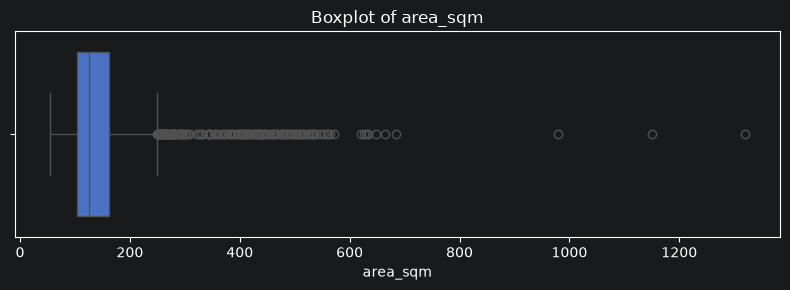

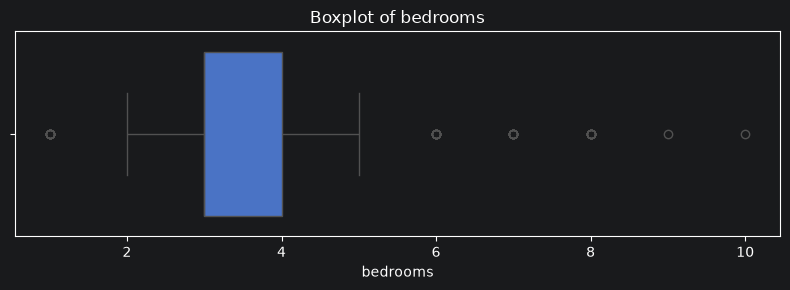

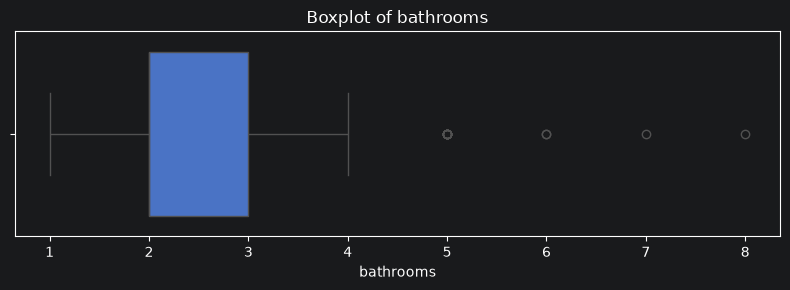

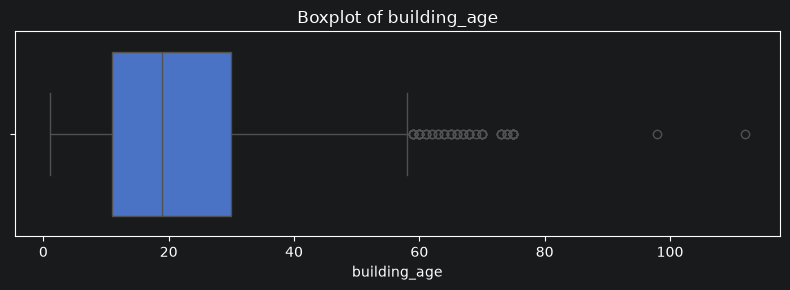

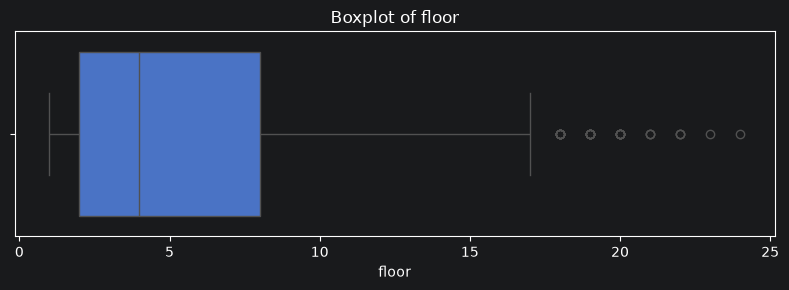

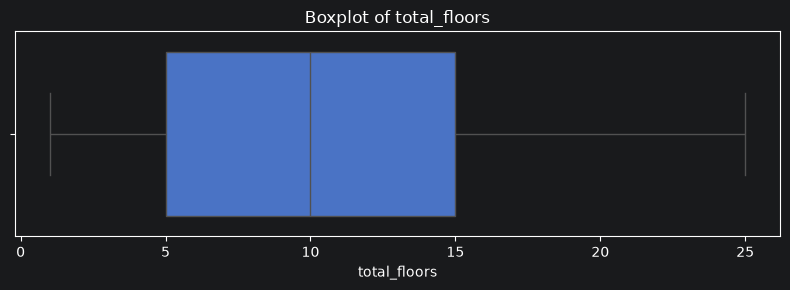

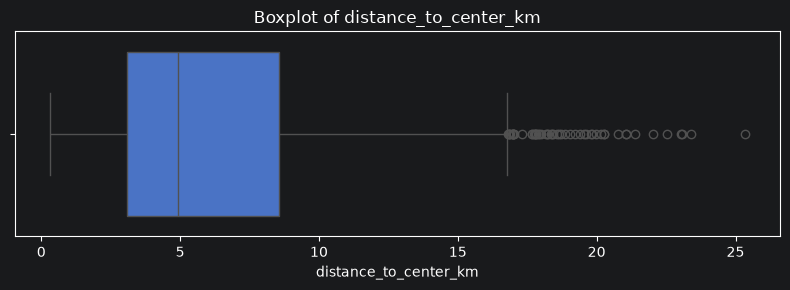

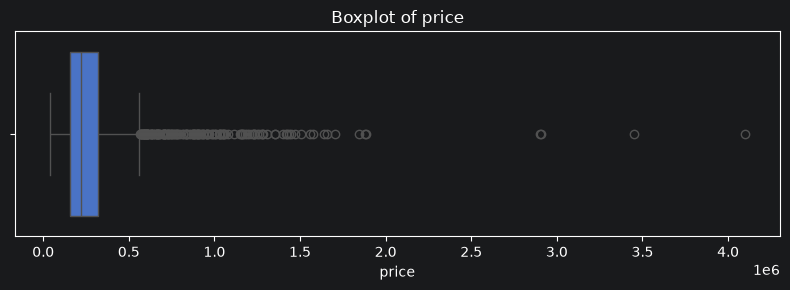

In [135]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

outlier_summary = []

for column in numerical_columns:
    values = df[column].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_bound) | (values > upper_bound)
    ).sum()

    outlier_summary.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(outlier_count),
        "Outlier Percentage": round(
            outlier_count / len(values) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)



print("We visualize outlier candidates:")
for column in numerical_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

##### Verify that the cleaned dataset has the expected data types.

In [138]:
dtype_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique(dropna=True)
})

display(dtype_summary)

df.info()

for column in ["price", "area", "bedrooms"]:
    if column in df.columns:
        print(
            f"{column}: "
            f"{'Numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'Not numeric'}"
        )


,Data Type,Missing Values,Unique Values
property_id,string,0,2100
location,string,0,7
area_sqm,float64,31,1192
bedrooms,int64,0,10
bathrooms,float64,42,8
property_type,string,0,3
building_age,float64,52,75
floor,float64,21,24
total_floors,int64,0,25
has_parking,bool,0,2


<class 'pandas.DataFrame'>
Index: 2100 entries, 0 to 2134
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   property_id            2100 non-null   string 
 1   location               2100 non-null   string 
 2   area_sqm               2069 non-null   float64
 3   bedrooms               2100 non-null   int64  
 4   bathrooms              2058 non-null   float64
 5   property_type          2100 non-null   string 
 6   building_age           2048 non-null   float64
 7   floor                  2079 non-null   float64
 8   total_floors           2100 non-null   int64  
 9   has_parking            2100 non-null   bool   
 10  has_elevator           2100 non-null   bool   
 11  distance_to_center_km  2069 non-null   float64
 12  renovation_status      2037 non-null   string 
 13  price                  2100 non-null   int64  
dtypes: bool(2), float64(5), int64(3), string(4)
memory usage: 217.4 KB
price

##### Validate the cleaned dataset and summarize the changes.


In [141]:
initial_rows = len(df)
initial_columns = df.shape[1]
initial_missing_values = int(df.isnull().sum().sum())
initial_duplicates = int(df.duplicated().sum())

final_summary = {
    "Initial Rows": initial_rows,
    "Final Rows": len(df),
    "Rows Removed": initial_rows - len(df),
    "Initial Columns": initial_columns,
    "Final Columns": df.shape[1],
    "Initial Missing Values": initial_missing_values,
    "Final Missing Values": int(df.isnull().sum().sum()),
    "Initial Duplicate Rows": initial_duplicates,
    "Final Duplicate Rows": int(df.duplicated().sum())
}

display(pd.DataFrame(
    final_summary.items(),
    columns=["Metric", "Value"]
))

print("\nRemaining missing values by column:")
display(df.isnull().sum().to_frame(name="Missing Count"))

print("\nFinal data types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nFinal dataset shape:", df.shape)

,Metric,Value
0,Initial Rows,2100
1,Final Rows,2100
2,Rows Removed,0
3,Initial Columns,14
4,Final Columns,14
5,Initial Missing Values,240
6,Final Missing Values,240
7,Initial Duplicate Rows,0
8,Final Duplicate Rows,0



Remaining missing values by column:


,Missing Count
property_id,0
location,0
area_sqm,31
bedrooms,0
bathrooms,42
property_type,0
building_age,52
floor,21
total_floors,0
has_parking,0



Final data types:


,Data Type
property_id,string
location,string
area_sqm,float64
bedrooms,int64
bathrooms,float64
property_type,string
building_age,float64
floor,float64
total_floors,int64
has_parking,bool



Final dataset shape: (2100, 14)


### Part 3 — Exploratory Data Analysis (EDA)


In [2]:
sns.set_theme(style="whitegrid")

PLOTS_DIR = Path("../outputs/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print("EDA setup completed.")
print(f"Plots will be saved to: {PLOTS_DIR.resolve()}")

EDA setup completed.
Plots will be saved to: C:\Users\LOQ\Desktop\real-estate-price-prediction\outputs\plots


##### Distribution of Property Prices

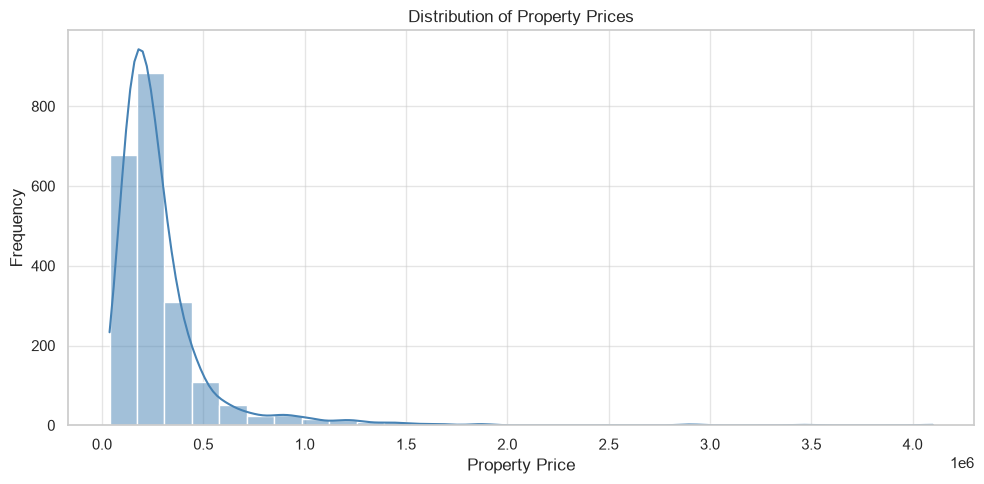

In [149]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", kde=True, bins=30,    color="steelblue"
)

plt.title("Distribution of Property Prices")
plt.xlabel("Property Price")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(PLOTS_DIR / "price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

##### Statistical Summary of Property Prices

In [150]:
price_stats = df["price"].agg(["mean", "median", "std"])

display(price_stats.to_frame(name="Price Statistics"))

,Price Statistics
mean,285081.451991
median,222000.000000
std,258097.736591


##### Average Prices by Property Type

,average_price,median_price,property_count
property_type,,,
villa,1.045918e+06,931000.0,120
house,3.540484e+05,318500.0,310
apartment,2.189934e+05,199500.0,1705


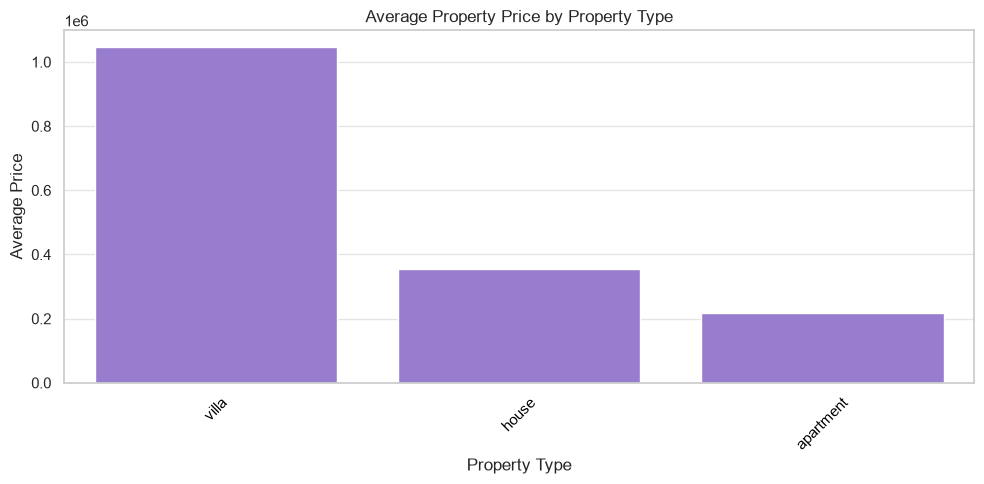

In [157]:
property_type_prices = (
    df.groupby("property_type", dropna=False)
      .agg(
          average_price=("price", "mean"),
          median_price=("price", "median"),
          property_count=("price", "count")
      )
      .sort_values("average_price", ascending=False)
)

display(property_type_prices)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=property_type_prices.reset_index(),
    x="property_type",
    y="average_price",
    color="mediumpurple"
)

plt.title("Average Property Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price")
plt.xticks(rotation=45,color="black")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "price_by_property_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### Relationship Between Property Area and Price

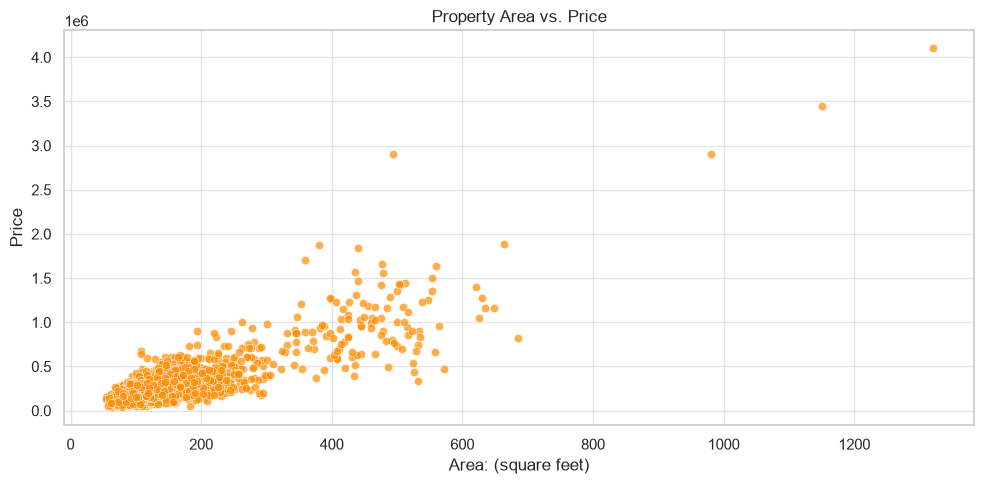

Correlation between area and price: 0.842


In [163]:
area_price_df = df[["area_sqm", "price"]].dropna()

plt.figure(figsize=(10, 5))

sns.scatterplot(data=area_price_df, x="area_sqm", y="price", color="darkorange", alpha=0.7)

plt.title("Property Area vs. Price")
plt.xlabel("Area: (square feet)")
plt.ylabel("Price")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "area_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

area_price_corr = area_price_df["area_sqm"].corr(area_price_df["price"])
print(f"Correlation between area and price: {area_price_corr:.3f}")

##### Relationship Between Bedrooms, Bathrooms, and Price

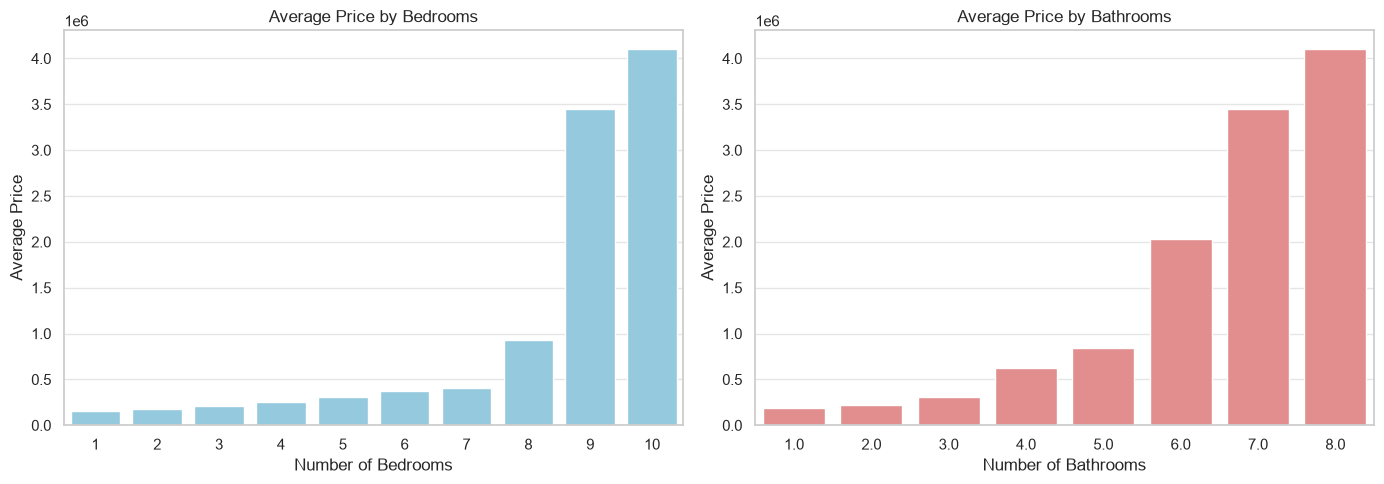

,bedrooms,average_price,property_count
0,1,1.556909e+05,55
1,2,1.785633e+05,387
2,3,2.083862e+05,683
3,4,2.516581e+05,503
4,5,3.113000e+05,195
5,6,3.713125e+05,128
6,7,4.062442e+05,43
7,8,9.267633e+05,139
8,9,3.450000e+06,1
9,10,4.100000e+06,1


,bathrooms,average_price,property_count
0,1.0,1.903074e+05,514
1,2.0,2.224318e+05,919
2,3.0,3.091118e+05,434
3,4.0,6.233359e+05,167
4,5.0,8.444904e+05,52
5,6.0,2.034750e+06,2
6,7.0,3.450000e+06,1
7,8.0,4.100000e+06,1


In [168]:
bedroom_prices = (
    df.groupby("bedrooms")
      .agg(
          average_price=("price", "mean"),
          property_count=("price", "count")
      )
    .reset_index()
    .sort_values("bedrooms")
)

bathroom_prices = (
    df.groupby("bathrooms")
      .agg(
          average_price=("price", "mean"),
          property_count=("price", "count")
      )
    .reset_index()
    .sort_values("bathrooms")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data = bedroom_prices,
    x="bedrooms",
    y="average_price",
    ax=axes[0],
    color = "skyblue"
)
axes[0].set_title("Average Price by Bedrooms")
axes[0].set_xlabel("Number of Bedrooms")
axes[0].set_ylabel("Average Price")

sns.barplot(
    data = bathroom_prices,
    x="bathrooms",
    y="average_price",
    ax=axes[1],
    color = "lightcoral"
)
axes[1].set_title("Average Price by Bathrooms")
axes[1].set_xlabel("Number of Bathrooms")
axes[1].set_ylabel("Average Price")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "price_by_bedrooms_bathrooms.png", dpi=300, bbox_inches="tight")
plt.show()

display(bedroom_prices)
display(bathroom_prices)


##### Average Property Prices by Location

,location,average_price,property_count
0,Sabail,398722.727273,220
1,Nasimi,331628.985507,345
2,Narimanov,324306.089744,312
3,Yasamal,322663.636364,330
4,Khatai,252765.230769,325
5,Baku,235284.146341,246
6,Binagadi,164780.952381,357


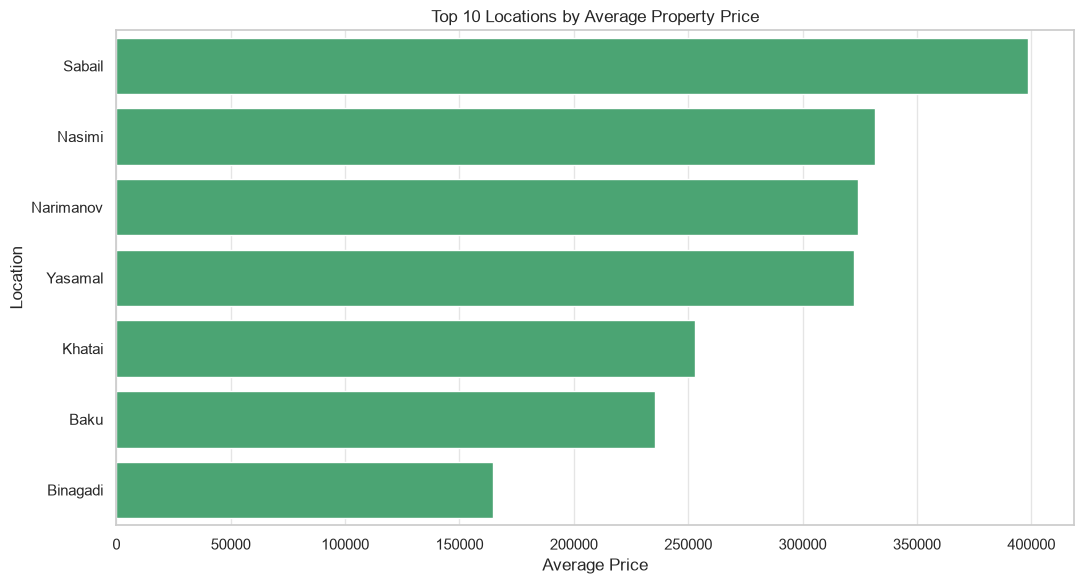

In [170]:
location_prices = (
    df.groupby("location")
      .agg(
          average_price=("price", "mean"),
          property_count=("price", "count")
      )
      .sort_values("average_price", ascending=False)
)

top_locations = location_prices.head(10).reset_index()

display(top_locations)

plt.figure(figsize=(11,6))

sns.barplot(
    data=top_locations,
    x="average_price",
    y="location",
    color="mediumseagreen"
)

plt.title("Top 10 Locations by Average Property Price")
plt.xlabel("Average Price")
plt.ylabel("Location")
plt.tight_layout()

plt.savefig(PLOTS_DIR / "price_by_location.png", dpi=300, bbox_inches="tight")
plt.show()

##### Differences in Price Between Property Types

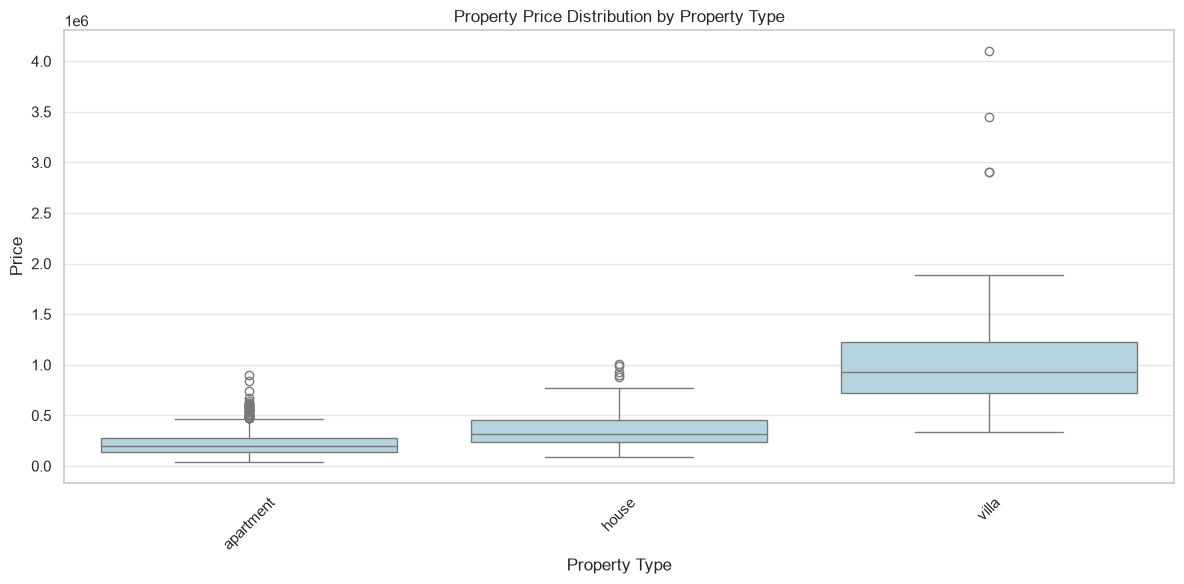

In [178]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="property_type",
    y="price",
    color="lightblue",
)

plt.title("Property Price Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(PLOTS_DIR / "price_boxplot_by_property_type.png", dpi=300, bbox_inches="tight")
plt.show()

##### ANOVA

In [4]:
from scipy.stats import f_oneway

anova_data = df[["property_type", "price"]].dropna()

groups = [
    group["price"].to_numpy()
    for _, group in anova_data.groupby("property_type")
    if len(group) >= 2
]

if len(groups) >= 2:
    f_statistic, p_value = f_oneway(*groups)

    print(f"F-statistic: {f_statistic:.3f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Conclusion: At least one group mean differs statistically.")
    else:
        print("Conclusion: There is insufficient evidence of a difference in group means.")
else:
    print("ANOVA could not be performed: insufficient groups.")

F-statistic: 1310.337
P-value: 0.000000
Conclusion: At least one group mean differs statistically.


##### Correlation Between Numerical Features and Price

,Correlation with Price
area_sqm,0.842036
bedrooms,0.643736
bathrooms,0.575826
total_floors,-0.300855
distance_to_center_km,-0.255651
floor,-0.204991
building_age,-0.172642


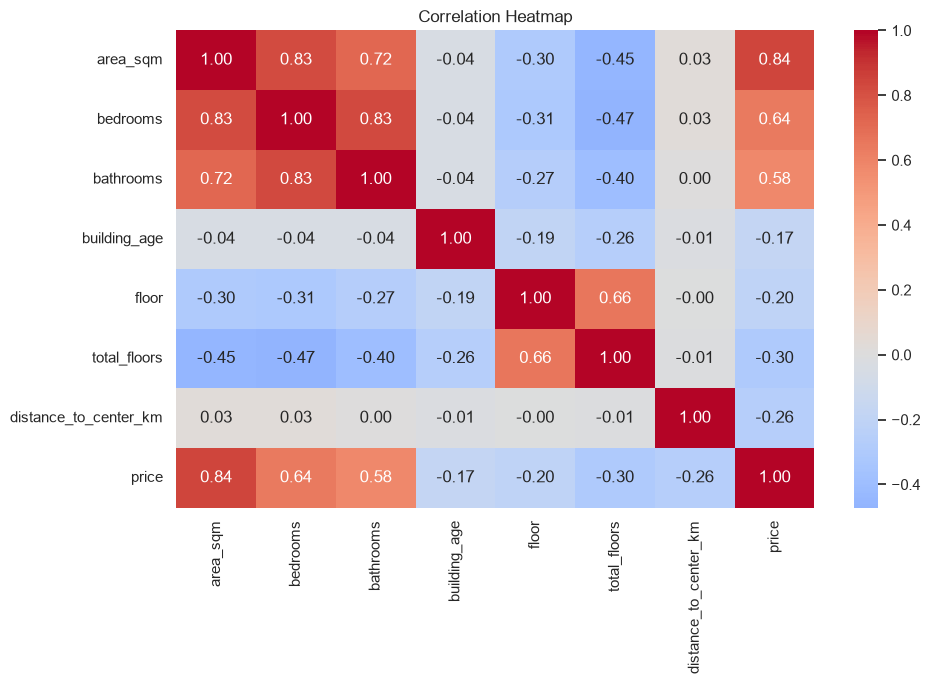

In [18]:
numeric_df = df.select_dtypes(include="number")

if "price" not in numeric_df.columns:
    raise ValueError("The target column 'price' must be numeric.")

correlation_matrix = numeric_df.corr()

price_correlations = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)

display(price_correlations.to_frame(name="Correlation with Price"))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    # cbar=True,
    # square=True,
    # linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

##### Potential Outliers in Property Prices and Areas


Column: price
Lower bound: -90375.00
Upper bound: 564625.00
Potential outliers: 161

Column: area_sqm
Lower bound: 15.75
Upper bound: 247.75
Potential outliers: 182


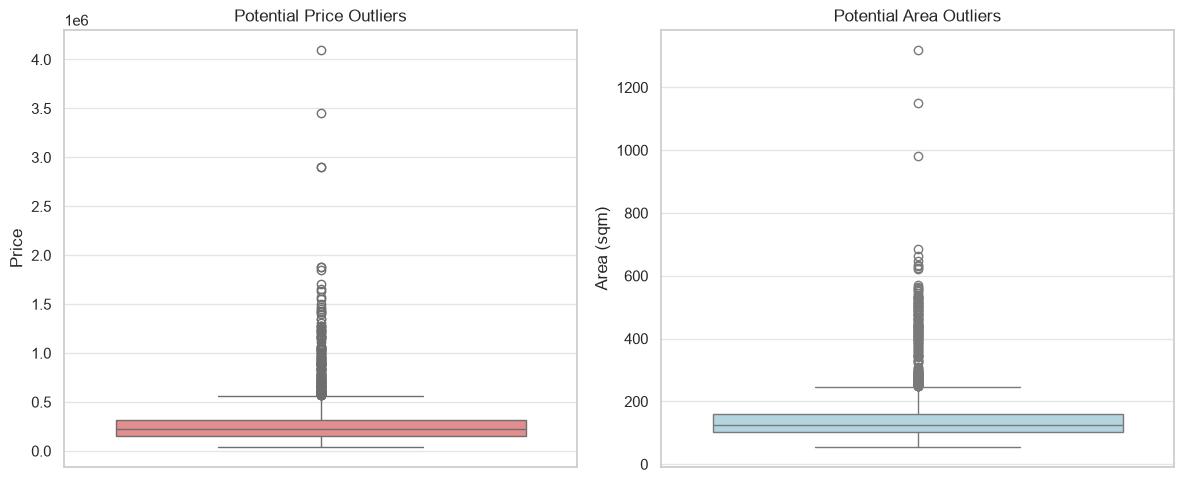

In [25]:
def detect_iqr_outliers(data,column):
    values = data[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = data[
        data[column].notna()
        & ((data[column] < lower_bound) | (data[column] > upper_bound))
    ]

    print(f"\nColumn: {column}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")

    return outliers

price_outliers = detect_iqr_outliers(df,"price")
area_outliers=  detect_iqr_outliers(df,"area_sqm")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    y=df["price"],
    ax=axes[0],
    color="lightcoral"
)
axes[0].set_title("Potential Price Outliers")
axes[0].set_ylabel("Price")
sns.boxplot(
    y=df["area_sqm"],
    ax=axes[1],
    color="lightblue"
)
axes[1].set_title("Potential Area Outliers")
axes[1].set_ylabel("Area (sqm)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "price_area_outliers.png", dpi=300, bbox_inches="tight")
plt.show()



##### Conclusions from Exploratory Data Analysis

In [26]:
print("EDA SUMMARY")
print("=" * 50)

print("\n1. Property prices:")
print(f"Mean: {df['price'].mean():.2f}")
print(f"Median: {df['price'].median():.2f}")
print(f"Standard deviation: {df['price'].std():.2f}")

if "area" in df.columns:
    correlation = df[["area", "price"]].corr().iloc[0, 1]
    print(f"\n2. Area-price correlation: {correlation:.3f}")

if "property_type" in df.columns:
    type_means = df.groupby("property_type")["price"].mean().dropna()
    if not type_means.empty:
        print(f"\n3. Highest average price by property type: {type_means.idxmax()}")
        print(f"Average price: {type_means.max():.2f}")

if "location" in df.columns:
    location_means = df.groupby("location")["price"].mean().dropna()
    if not location_means.empty:
        print(f"\n4. Highest average price location: {location_means.idxmax()}")
        print(f"Average price: {location_means.max():.2f}")

print("\n5. Potential outliers:")
print(f"Price outliers: {len(price_outliers)}")
print(f"Area outliers: {len(area_outliers)}")

print("\nReview the plots and statistics above before writing the final conclusions.")

EDA SUMMARY

1. Property prices:
Mean: 285081.45
Median: 222000.00
Standard deviation: 258097.74

3. Highest average price by property type: villa
Average price: 1045917.50

4. Highest average price location: Sabail
Average price: 398722.73

5. Potential outliers:
Price outliers: 161
Area outliers: 182

Review the plots and statistics above before writing the final conclusions.


### Part 4 — Feature Engineering

##### Separate target and input features


In [6]:
TARGET = "price"

EXCLUDED_COLUMNS = ["property_id"]

X = df.drop(columns=[TARGET] + EXCLUDED_COLUMNS)
y = df[TARGET]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input features shape: (2135, 12)
Target shape: (2135,)


,location,area_sqm,bedrooms,bathrooms,property_type,building_age,floor,total_floors,has_parking,has_elevator,distance_to_center_km,renovation_status
0,Nasimi,108.7,3,2.0,apartment,4.0,10.0,17,True,True,NaN,renovated
1,Nasimi,118.1,3,2.0,apartment,9.0,13.0,17,False,True,2.68,needs_renovation
2,Baku,80.7,2,1.0,apartment,NaN,22.0,24,False,True,10.32,good
3,Sabail,294.3,8,5.0,house,48.0,3.0,3,True,False,2.67,needs_renovation
4,Binagadi,96.6,3,2.0,apartment,40.0,4.0,16,True,True,3.55,needs_renovation


0    466000
1    244000
2    117000
3    506000
4     76000
Name: price, dtype: int64

##### Identify numerical and categorical features

In [5]:
numerical_features = [
    "area_sqm",
    "bedrooms",
    "bathrooms",
    "building_age",
    "floor",
    "total_floors",
    "distance_to_center_km"
]

categorical_features = [
    "location",
    "property_type",
    "has_parking",
    "has_elevator",
    "renovation_status"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['area_sqm', 'bedrooms', 'bathrooms', 'building_age', 'floor', 'total_floors', 'distance_to_center_km']

Categorical features:
['location', 'property_type', 'has_parking', 'has_elevator', 'renovation_status']


##### Check columns to exclude

In [7]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nUnique property IDs:", df["property_id"].nunique())
print("Total rows:", len(df))

Dataset columns:
['property_id', 'location', 'area_sqm', 'bedrooms', 'bathrooms', 'property_type', 'building_age', 'floor', 'total_floors', 'has_parking', 'has_elevator', 'distance_to_center_km', 'renovation_status', 'price']

Unique property IDs: 2100
Total rows: 2135


##### Split the dataset into training and testing sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1708, 12)
Testing features: (427, 12)
Training target: (1708,)
Testing target: (427,)


##### Build the preprocessing pipeline

In [9]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

##### Prevent data leakage

In [10]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (1708, 24)
Processed testing shape: (427, 24)


##### Verify transformed features

In [11]:
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 20 transformed features:")
print(feature_names[:20])

print("\nTraining matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

assert X_train_processed.shape[1] == X_test_processed.shape[1]
assert X_train_processed.shape[1] == len(feature_names)

print("\nFeature transformation completed successfully.")

Number of transformed features: 24

First 20 transformed features:
['num__area_sqm' 'num__bedrooms' 'num__bathrooms' 'num__building_age'
 'num__floor' 'num__total_floors' 'num__distance_to_center_km'
 'cat__location_Baku' 'cat__location_Binagadi' 'cat__location_Khatai'
 'cat__location_Narimanov' 'cat__location_Nasimi' 'cat__location_Sabail'
 'cat__location_Yasamal' 'cat__property_type_apartment'
 'cat__property_type_house' 'cat__property_type_villa'
 'cat__has_parking_False' 'cat__has_parking_True'
 'cat__has_elevator_False']

Training matrix shape: (1708, 24)
Testing matrix shape: (427, 24)

Feature transformation completed successfully.


##### Recommended: use the preprocessor inside the model pipeline

In [12]:
from sklearn.linear_model import LinearRegression

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)

print("Predictions:", y_pred[:5])

Predictions: [350267.3952885  197368.77559516 205413.85489877 298393.66103419
  25867.23479549]


### Part 5 — Model Training


##### Prepare target and split the dataset

In [15]:
df_model = df.dropna(subset=["price"]).copy()

TARGET = "price"
EXCLUDED_COLUMNS = ["property_id"]

X = df_model.drop(columns=[TARGET] + EXCLUDED_COLUMNS)
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training target mean:", round(y_train.mean(), 2))
print("Testing target mean:", round(y_test.mean(), 2))

Training samples: 1708
Testing samples: 427
Training target mean: 277039.75
Testing target mean: 317248.24


##### Create preprocessing pipeline

In [16]:
numerical_features = [
    "area_sqm",
    "bedrooms",
    "bathrooms",
    "building_age",
    "floor",
    "total_floors",
    "distance_to_center_km"
]

categorical_features = [
    "location",
    "property_type",
    "has_parking",
    "has_elevator",
    "renovation_status"
]


def create_preprocessor():
    numerical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, numerical_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

##### Create the four models

In [17]:
models = {
    "Dummy Regressor": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Hist Gradient Boosting Regressor": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        random_state=42
    )
}

##### Train models and generate predictions

In [21]:
trained_models = {}
predictions = {}
results = []

for model_name, estimator in models.items():
    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", create_preprocessor()),
            ("model", estimator)
        ]
    )

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)
    trained_models[model_name] = model_pipeline
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

    print(f"{model_name} trained successfully.")

Dummy Regressor trained successfully.
Linear Regression trained successfully.
Random Forest Regressor trained successfully.
Hist Gradient Boosting Regressor trained successfully.


##### Compare model performance

In [22]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)
display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,58068.221,109782.601,0.880
1,Random Forest Regressor,51501.900,128233.163,0.837
2,Hist Gradient Boosting Regressor,54102.066,154026.625,0.764
3,Dummy Regressor,167196.198,319686.723,-0.016


##### Check unrealistic predictions

In [23]:
prediction_check = []
for model_name,y_pred in predictions.items():
    negative_count = int(np.sum(y_pred < 0))
    prediction_check.append({
        "Model": model_name,
        "Minimum prediction": np.min(y_pred),
        "Maximum prediction": np.max(y_pred),
        "Negative predictions": negative_count
    })
prediction_check = pd.DataFrame(prediction_check)
display(prediction_check.round(2))

,Model,Minimum prediction,Maximum prediction,Negative predictions
0,Dummy Regressor,277039.75,277039.75,0
1,Linear Regression,-81331.35,2512773.64,8
2,Random Forest Regressor,63520.00,1969395.00,0
3,Hist Gradient Boosting Regressor,59522.59,1779649.82,0


##### Save results

In [27]:
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False,
)

test_predictions = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    **predictions
})

test_predictions.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
)
print("Model comparison saved successfully.")
print("Test predictions saved successfully.")

Model comparison saved successfully.
Test predictions saved successfully.


### Part 6 — Model Evaluation and Comparison


##### Calculate model metrics

In [28]:
results = []

for model_name, y_pred in predictions.items():
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Dummy Regressor,167196.198,319686.723,-0.016
1,Linear Regression,58068.221,109782.601,0.880
2,Random Forest Regressor,51501.900,128233.163,0.837
3,Hist Gradient Boosting Regressor,54102.066,154026.625,0.764


##### Compare all models

In [29]:
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)
display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,58068.221,109782.601,0.880
1,Random Forest Regressor,51501.900,128233.163,0.837
2,Hist Gradient Boosting Regressor,54102.066,154026.625,0.764
3,Dummy Regressor,167196.198,319686.723,-0.016


##### Identify the best MAE and RMSE models

In [32]:
best_mae_model = results_df.loc[
    results_df["MAE"].idxmin()
]
best_rmse_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("Model with the lowest MAE:")
print(best_mae_model)

print("\nModel with the lowest RMSE:")
print(best_rmse_model)

Model with the lowest MAE:
Model    Random Forest Regressor
MAE                 51501.900468
RMSE               128233.163245
R2                      0.836515
Name: 1, dtype: object

Model with the lowest RMSE:
Model    Linear Regression
MAE            58068.22125
RMSE         109782.601171
R2                0.880176
Name: 0, dtype: object


##### Compare against the baseline

In [33]:
baseline_row = results_df[
    results_df["Model"] == "Dummy Regressor"
]

if baseline_row.empty:
    print("Dummy Regressor baseline was not found.")
else:
    baseline_mae = baseline_row["MAE"].iloc[0]
    baseline_rmse = baseline_row["RMSE"].iloc[0]

    results_df["MAE improvement (%)"] = (
        (baseline_mae - results_df["MAE"])
        / baseline_mae * 100
    )

    results_df["RMSE improvement (%)"] = (
        (baseline_rmse - results_df["RMSE"])
        / baseline_rmse * 100
    )

    display(results_df.round(3))

,Model,MAE,RMSE,R2,MAE improvement (%),RMSE improvement (%)
0,Linear Regression,58068.221,109782.601,0.880,65.269,65.659
1,Random Forest Regressor,51501.900,128233.163,0.837,69.197,59.888
2,Hist Gradient Boosting Regressor,54102.066,154026.625,0.764,67.642,51.820
3,Dummy Regressor,167196.198,319686.723,-0.016,0.000,0.000


##### Plot actual vs predicted prices

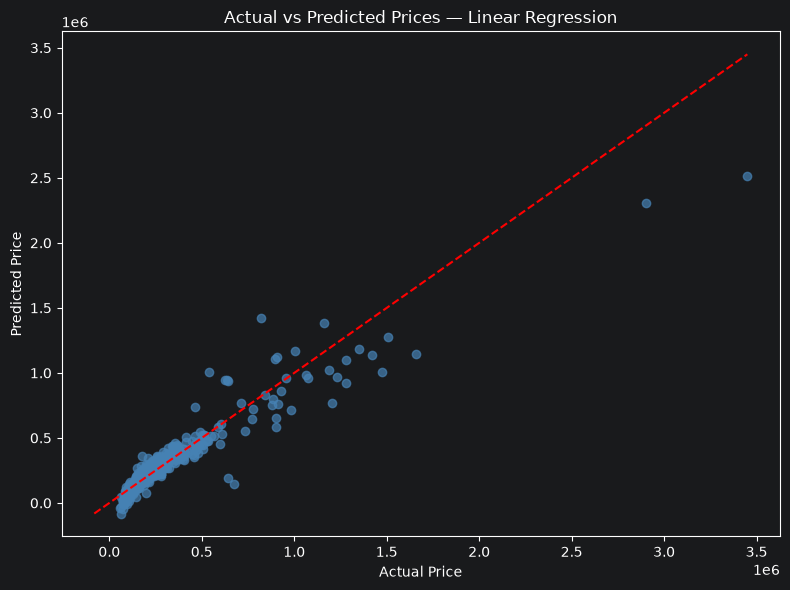

In [54]:
best_model_name = results_df.iloc[0]["Model"]
best_model_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_model_predictions,
    alpha=0.7,
    color="steelblue"
)

min_price = min(
    y_test.min(),
    best_model_predictions.min()
)

max_price = max(
    y_test.max(),
    best_model_predictions.max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red"
)

plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%%sql


##### Analyze residuals

$$
\text{Residual} = \text{Actual Price} - \text{Predicted Price}
$$

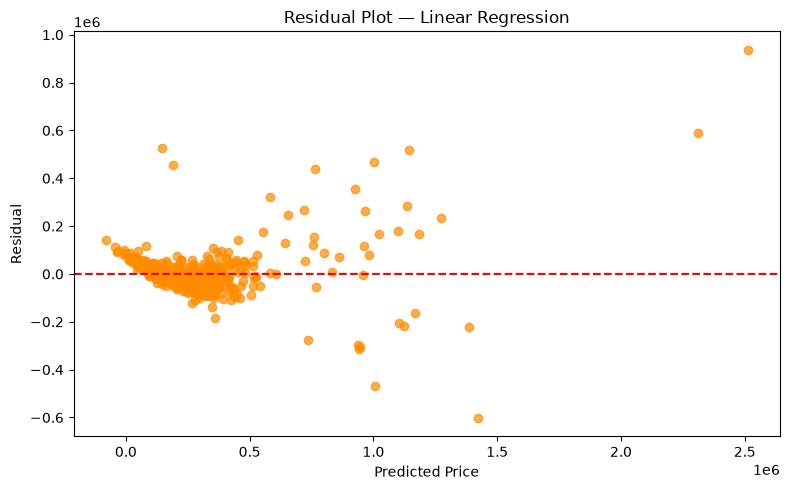

In [36]:
residuals = y_test.to_numpy() - best_model_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    best_model_predictions,
    residuals,
    alpha=0.7,
    color="darkorange"
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red"
)

plt.title(f"Residual Plot — {best_model_name}")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### Residual distribution

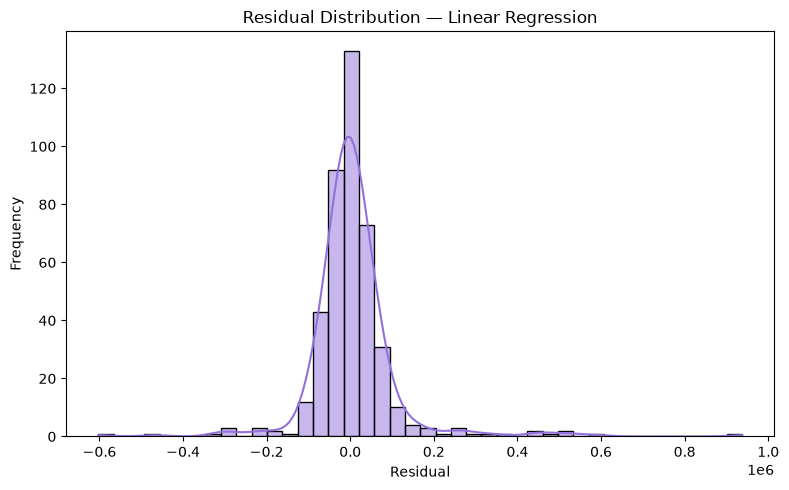

Mean residual: 6963.851
Median absolute error: 32820.919
Maximum absolute error: 937226.355


In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    color="mediumpurple"
)

plt.title(f"Residual Distribution — {best_model_name}")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", round(float(np.mean(residuals)), 3))
print("Median absolute error:", round(float(np.median(np.abs(residuals))), 3))
print("Maximum absolute error:", round(float(np.max(np.abs(residuals))), 3))

##### Check prediction errors

In [38]:
error_analysis = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": best_model_predictions,
    "Residual": residuals,
    "Absolute Error": np.abs(residuals)
})

display(
    error_analysis.sort_values(
        by="Absolute Error",
        ascending=False
    ).head(10).round(2)
)

,Actual Price,Predicted Price,Residual,Absolute Error
348,3450000,2512773.64,937226.36,937226.36
293,818500,1420972.02,-602472.02,602472.02
271,2900000,2309429.69,590570.31,590570.31
284,673700,146380.23,527319.77,527319.77
179,1660000,1141891.64,518108.36,518108.36
162,1472000,1003306.02,468693.98,468693.98
30,541500,1008438.21,-466938.21,466938.21
302,643800,189754.02,454045.98,454045.98
384,1204500,764881.65,439618.35,439618.35
328,1278000,924514.55,353485.45,353485.45


##### Select the most suitable model

In [40]:
best_mae_name = results_df.loc[
    results_df["MAE"].idxmin(), "Model"
]

best_rmse_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_r2_name = results_df.loc[
    results_df["R2"].idxmax(), "Model"
]

print("Lowest MAE:", best_mae_name)
print("Lowest RMSE:", best_rmse_name)
print("Highest R2:", best_r2_name)

print("\nModel metrics:")
display(results_df.round(3))

Lowest MAE: Random Forest Regressor
Lowest RMSE: Linear Regression
Highest R2: Linear Regression

Model metrics:


,Model,MAE,RMSE,R2,MAE improvement (%),RMSE improvement (%)
0,Linear Regression,58068.221,109782.601,0.880,65.269,65.659
1,Random Forest Regressor,51501.900,128233.163,0.837,69.197,59.888
2,Hist Gradient Boosting Regressor,54102.066,154026.625,0.764,67.642,51.820
3,Dummy Regressor,167196.198,319686.723,-0.016,0.000,0.000


##### Save evaluation results

In [41]:
OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

error_analysis.to_csv(
    OUTPUT_DIR / "prediction_error_analysis.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


### Part 7 — Practical Price Predictions

##### Display Actual and Predicted Prices

In [42]:
best_model_name = results_df.sort_values(
    by="RMSE", ascending=True
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

test_predictions = pd.DataFrame({
    "Actual_Price": y_test,
    "Predicted_Price": y_pred
}, index=y_test.index)

print("Best model:", best_model_name)
display(test_predictions.head(10).round(2))

Best model: Linear Regression


,Actual_Price,Predicted_Price
1429,458000,350267.40
231,165000,197368.78
2019,143500,205413.85
297,242500,298393.66
2053,74500,25867.23
298,167000,195804.44
1837,335500,345248.95
719,189000,266408.15
70,95500,69966.65
1483,151000,106682.77


##### Calculate Absolute Prediction Errors

In [43]:
test_predictions["Absolute_Error"] = np.abs(
    test_predictions["Actual_Price"]
    - test_predictions["Predicted_Price"]
)

test_predictions["Residual"] = (
    test_predictions["Actual_Price"]
    - test_predictions["Predicted_Price"]
)

display(test_predictions.head(10).round(2))

,Actual_Price,Predicted_Price,Absolute_Error,Residual
1429,458000,350267.40,107732.60,107732.60
231,165000,197368.78,32368.78,-32368.78
2019,143500,205413.85,61913.85,-61913.85
297,242500,298393.66,55893.66,-55893.66
2053,74500,25867.23,48632.77,48632.77
298,167000,195804.44,28804.44,-28804.44
1837,335500,345248.95,9748.95,-9748.95
719,189000,266408.15,77408.15,-77408.15
70,95500,69966.65,25533.35,25533.35
1483,151000,106682.77,44317.23,44317.23


##### Identify Records with the Largest Errors

In [44]:
largest_errors = test_predictions.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print("Properties with the largest prediction errors:")
display(largest_errors.round(2))

Properties with the largest prediction errors:


,Actual_Price,Predicted_Price,Absolute_Error,Residual
1507,3450000,2512773.64,937226.36,937226.36
324,818500,1420972.02,602472.02,-602472.02
1655,2900000,2309429.69,590570.31,590570.31
707,673700,146380.23,527319.77,527319.77
1176,1660000,1141891.64,518108.36,518108.36
1436,1472000,1003306.02,468693.98,468693.98
679,541500,1008438.21,466938.21,-466938.21
1864,643800,189754.02,454045.98,454045.98
381,1204500,764881.65,439618.35,439618.35
2064,1278000,924514.55,353485.45,353485.45


##### Create an Input Record for a New Property

In [45]:
new_property = pd.DataFrame([{
    "area_sqm": 85,
    "bedrooms": 3,
    "bathrooms": 1,
    "building_age": 5,
    "floor": 3,
    "total_floors": 9,
    "distance_to_center_km": 4.0,
    "location": df["location"].mode().iloc[0],
    "property_type": df["property_type"].mode().iloc[0],
    "has_parking": df["has_parking"].mode().iloc[0],
    "has_elevator": df["has_elevator"].mode().iloc[0],
    "renovation_status": df["renovation_status"].mode().iloc[0]
}])

print("New property details:")
display(new_property)

New property details:


,area_sqm,bedrooms,bathrooms,building_age,floor,total_floors,distance_to_center_km,location,property_type,has_parking,has_elevator,renovation_status
0,85,3,1,5,3,9,4.0,Binagadi,apartment,False,True,renovated


##### Validate the New Property Before Prediction

In [46]:
def validate_property(property_data, reference_data):
    errors = []

    expected_columns = numerical_features + categorical_features

    missing = set(expected_columns) - set(property_data.columns)
    extra = set(property_data.columns) - set(expected_columns)

    if missing:
        errors.append(f"Missing columns: {sorted(missing)}")

    if extra:
        errors.append(f"Unexpected columns: {sorted(extra)}")

    if len(property_data) != 1:
        errors.append("Exactly one property record is required.")

    if errors:
        return errors

    row = property_data.iloc[0]

    if property_data[expected_columns].isnull().any().any():
        errors.append("Input contains missing values.")

    for column in numerical_features:
        value = row[column]

        if pd.isna(value):
            continue

        if not np.isfinite(value):
            errors.append(f"{column} must be a finite number.")
        elif value < 0:
            errors.append(f"{column} cannot be negative.")

    for column in ["bedrooms", "bathrooms", "building_age",
                   "floor", "total_floors"]:
        value = row[column]

        if pd.notna(value) and not float(value).is_integer():
            errors.append(f"{column} must be a whole number.")

    if (
        pd.notna(row["floor"])
        and pd.notna(row["total_floors"])
        and row["floor"] > row["total_floors"]
    ):
        errors.append("floor cannot exceed total_floors.")

    for column in categorical_features:
        valid_values = set(reference_data[column].dropna().unique())

        if row[column] not in valid_values:
            errors.append(
                f"Unknown category in {column}: {row[column]}"
            )

    return errors


validation_errors = validate_property(new_property, X_train)

if validation_errors:
    print("Validation failed:")
    for error in validation_errors:
        print("-", error)
else:
    print("Validation successful.")

Validation successful.


##### Predict the Price of the New Property

In [47]:
validation_errors = validate_property(new_property, X_train)

if validation_errors:
    raise ValueError(
        "Prediction stopped because validation failed:\n"
        + "\n".join(validation_errors)
    )

predicted_price = best_model.predict(new_property)[0]

print("Selected model:", best_model_name)
print(f"Predicted property price: {predicted_price:,.2f}")

Selected model: Linear Regression
Predicted property price: 110,068.68


##### Explain Prediction Limitations

### Limitations of the Generated Prediction

- **Data quality:** Incorrect or incomplete dataset records can reduce model accuracy.
- **Market changes:** The model may not reflect current real-estate market prices.
- **Missing features:** Factors such as exact address, view, legal status, and nearby infrastructure may affect property prices.
- **Prediction errors:** The predicted price is an estimate and may differ from the actual selling price.
- **Limited training data:** Predictions may be less reliable for locations or property types with few training examples.
- **Input validation:** Validation checks data format and consistency but cannot guarantee that the information provided is factually correct.

The predicted price should be treated as an estimate, not a guaranteed market value or professional property valuation.